In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ROOT = Path("../..")
PROCESSED = ROOT / "data" / "processed"
FIGURES = Path("../figures")

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_parquet(PROCESSED / "aria_campania_orario.parquet")
df.shape
df.head()

,Stazione,Descrizione,Inquinante,Data_ora,Valore,Um
0,IT2283A,OTTATI - ALBURNI,PM10,2023-03-20,18.3,µg/m3
1,IT2227A,AVELLINO - SCUOLA ALIGHIERI,PM10,2023-03-20,78.2,µg/m3
2,IT2226A,Pomigliano d'Arco Area ASI,PM10,2023-03-20,31.6,µg/m3
3,IT0936A,AV41 SCUOLA V CIRCOLO,PM10,2023-03-20,73.8,µg/m3
4,IT2228A,BENEVENTO CAMPO SPORTIVO,PM10,2023-03-20,40.1,µg/m3


media dei valore per giornata

In [4]:
df["giorno"] = df["Data_ora"].dt.normalize()

g = df.groupby(["Stazione", "Inquinante", "giorno"])["Valore"].agg(["mean", "count"]).reset_index()
giornaliero = g[g["count"] >= 18]

print("Medie giornaliere valide:", len(giornaliero), "su", len(g))
giornaliero.head()

Medie giornaliere valide: 191170 su 200769


,Stazione,Inquinante,giorno,mean,count
0,IT0898A,C6H6,2023-03-20,3.037500,24
1,IT0898A,C6H6,2023-03-21,1.579167,24
2,IT0898A,C6H6,2023-03-22,2.554167,24
3,IT0898A,C6H6,2023-03-23,2.354167,24
4,IT0898A,C6H6,2023-03-24,1.491667,24


grafica di distribuzione

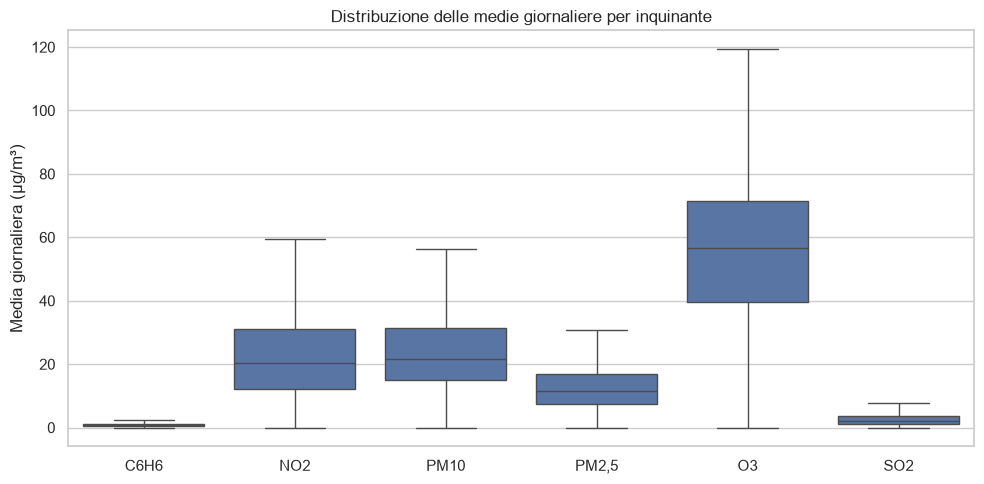

In [5]:
dati = giornaliero[giornaliero["Inquinante"] != "CO"]

plt.figure(figsize=(10, 5))
sns.boxplot(data=dati, x="Inquinante", y="mean", showfliers=False)
plt.xlabel("")
plt.ylabel("Media giornaliera (µg/m³)")
plt.title("Distribuzione delle medie giornaliere per inquinante")
plt.tight_layout()
plt.savefig(FIGURES / "distribuzione_inquinanti.png", dpi=200)
plt.show()

media giornaliera di rete

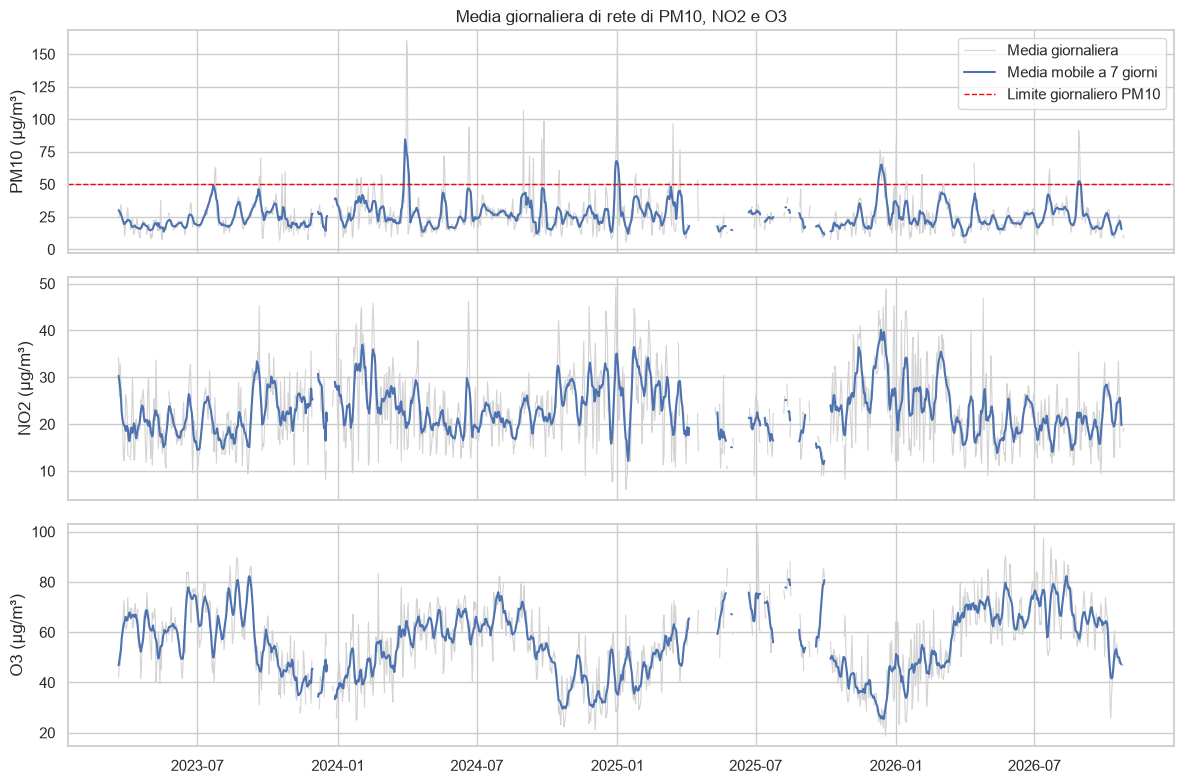

In [6]:
inquinanti = ["PM10", "NO2", "O3"]

rete = (giornaliero[giornaliero["Inquinante"].isin(inquinanti)]
        .groupby(["giorno", "Inquinante"])["mean"].mean()
        .unstack())
rete = rete.asfreq("D")
media7 = rete.rolling(7, center=True, min_periods=4).mean()

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, inq in zip(axes, inquinanti):
    ax.plot(rete.index, rete[inq], color="lightgray", linewidth=0.8, label="Media giornaliera")
    ax.plot(media7.index, media7[inq], linewidth=1.5, label="Media mobile a 7 giorni")
    ax.set_ylabel(f"{inq} (µg/m³)")

axes[0].axhline(50, color="red", linestyle="--", linewidth=1, label="Limite giornaliero PM10")
axes[0].legend(loc="upper right")
axes[0].set_title("Media giornaliera di rete di PM10, NO2 e O3")
plt.tight_layout()
plt.savefig(FIGURES / "andamento_temporale.png", dpi=200)
plt.show()

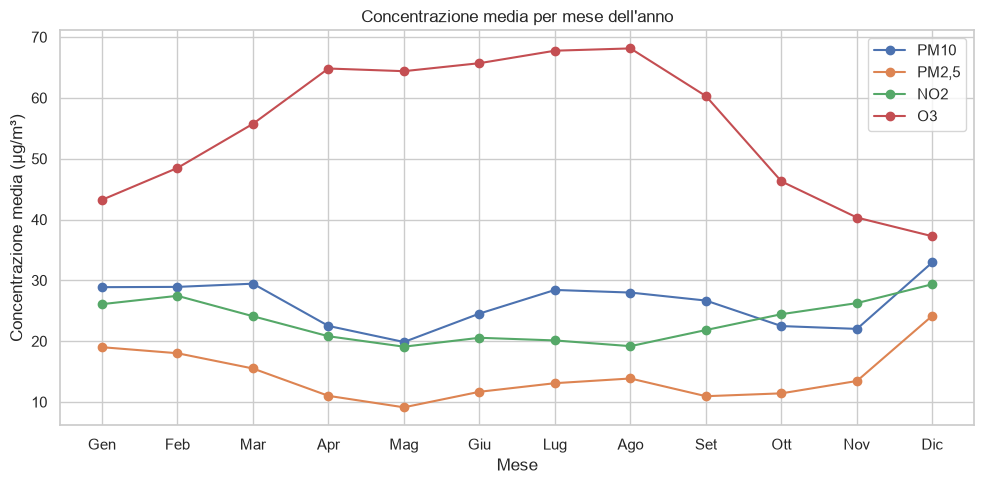

Inquinante   NO2    O3  PM10  PM2,5
mese                               
1           26.1  43.2  28.9   19.0
2           27.5  48.5  28.9   18.0
3           24.1  55.7  29.5   15.5
4           20.8  64.8  22.5   11.0
5           19.1  64.4  19.9    9.1
6           20.6  65.7  24.5   11.7
7           20.1  67.8  28.4   13.1
8           19.2  68.1  28.0   13.9
9           21.8  60.3  26.7   11.0
10          24.4  46.3  22.5   11.4
11          26.3  40.3  22.0   13.5
12          29.4  37.2  33.0   24.2

Giorni disponibili per mese:
mese
1      93
2      85
3     102
4      97
5     108
6     104
7     109
8     105
9     108
10    109
11     81
12     76
Name: giorno, dtype: int64


In [7]:
principali = ["PM10", "PM2,5", "NO2", "O3"]
mesi = ["Gen", "Feb", "Mar", "Apr", "Mag", "Giu", "Lug", "Ago", "Set", "Ott", "Nov", "Dic"]

dati = giornaliero[giornaliero["Inquinante"].isin(principali)].copy()
dati["mese"] = dati["giorno"].dt.month
mensile = dati.groupby(["mese", "Inquinante"])["mean"].mean().unstack()

plt.figure(figsize=(10, 5))
for inq in principali:
    plt.plot(mensile.index, mensile[inq], marker="o", label=inq)
plt.xticks(range(1, 13), mesi)
plt.xlabel("Mese")
plt.ylabel("Concentrazione media (µg/m³)")
plt.title("Concentrazione media per mese dell'anno")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "stagionalita_mensile.png", dpi=200)
plt.show()

print(mensile.round(1))
print("\nGiorni disponibili per mese:")
print(dati.groupby("mese")["giorno"].nunique())

C:\Users\toyem\AppData\Local\Temp\ipykernel_48504\906599125.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dati["giorno_sett"] = dati["giorno"].dt.dayofweek


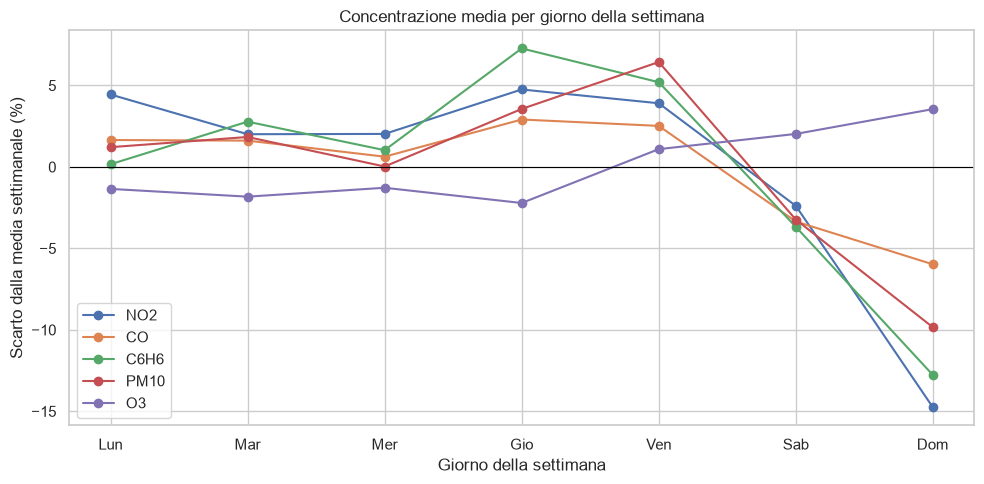

Inquinante   C6H6    CO    NO2     O3   PM10
giorno_sett                                 
0            1.00  0.49  24.02  55.36  26.39
1            1.03  0.49  23.46  55.10  26.55
2            1.01  0.49  23.46  55.40  26.08
3            1.07  0.50  24.09  54.88  27.00
4            1.05  0.50  23.89  56.73  27.75
5            0.96  0.47  22.45  57.26  25.23
6            0.87  0.46  19.60  58.11  23.51

Scarto dalla media settimanale (%):
Inquinante   C6H6   CO   NO2   O3  PM10
giorno_sett                            
0             0.2  1.7   4.4 -1.3   1.2
1             2.8  1.6   2.0 -1.8   1.8
2             1.0  0.6   2.0 -1.3   0.0
3             7.3  2.9   4.8 -2.2   3.6
4             5.2  2.5   3.9  1.1   6.4
5            -3.7 -3.3  -2.4  2.0  -3.2
6           -12.8 -6.0 -14.8  3.5  -9.8


In [8]:
scelti = ["NO2", "CO", "C6H6", "PM10", "O3"]
giorni = ["Lun", "Mar", "Mer", "Gio", "Ven", "Sab", "Dom"]

dati = giornaliero[giornaliero["Inquinante"].isin(scelti)].copy()
dati["giorno_sett"] = dati["giorno"].dt.dayofweek
sett = dati.groupby(["giorno_sett", "Inquinante"])["mean"].mean().unstack()
scarto = (sett / sett.mean() - 1) * 100

plt.figure(figsize=(10, 5))
for inq in scelti:
    plt.plot(scarto.index, scarto[inq], marker="o", label=inq)
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(range(7), giorni)
plt.xlabel("Giorno della settimana")
plt.ylabel("Scarto dalla media settimanale (%)")
plt.title("Concentrazione media per giorno della settimana")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "ciclo_settimanale.png", dpi=200)
plt.show()

print(sett.round(2))
print("\nScarto dalla media settimanale (%):")
print(scarto.round(1))

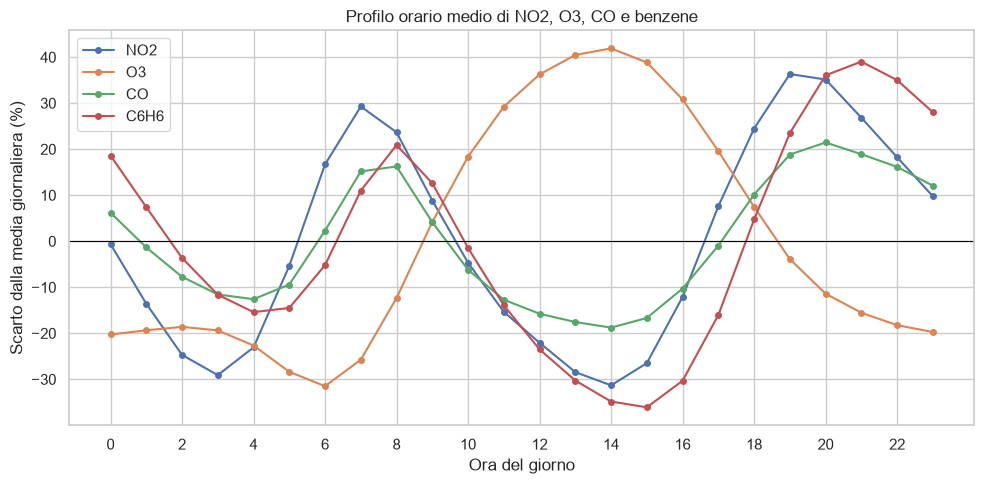

Inquinante  C6H6    CO    NO2     O3
ora                                 
0           1.19  0.51  22.77  44.92
1           1.07  0.48  19.80  45.43
2           0.96  0.45  17.25  45.85
3           0.88  0.43  16.24  45.42
4           0.85  0.42  17.63  43.57
5           0.86  0.44  21.68  40.35
6           0.95  0.50  26.74  38.59
7           1.11  0.56  29.62  41.82
8           1.21  0.56  28.33  49.38
9           1.13  0.50  24.94  58.68
10          0.99  0.45  21.84  66.68
11          0.86  0.42  19.40  72.80
12          0.77  0.41  17.85  76.75
13          0.70  0.40  16.39  79.13
14          0.65  0.39  15.74  79.93
15          0.64  0.40  16.84  78.22
16          0.70  0.43  20.14  73.68
17          0.84  0.48  24.65  67.36
18          1.05  0.53  28.52  60.53
19          1.24  0.58  31.23  54.14
20          1.36  0.59  30.96  49.91
21          1.39  0.58  29.06  47.58
22          1.35  0.56  27.09  46.06
23          1.28  0.54  25.14  45.21


In [9]:
gas = ["NO2", "O3", "CO", "C6H6"]

orario = df[df["Inquinante"].isin(gas)].copy()
orario["ora"] = orario["Data_ora"].dt.hour
profilo = orario.groupby(["ora", "Inquinante"])["Valore"].mean().unstack()
scarto_h = (profilo / profilo.mean() - 1) * 100

plt.figure(figsize=(10, 5))
for inq in gas:
    plt.plot(scarto_h.index, scarto_h[inq], marker="o", markersize=4, label=inq)
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(range(0, 24, 2))
plt.xlabel("Ora del giorno")
plt.ylabel("Scarto dalla media giornaliera (%)")
plt.title("Profilo orario medio di NO2, O3, CO e benzene")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "ciclo_giornaliero.png", dpi=200)
plt.show()

print(profilo.round(2))

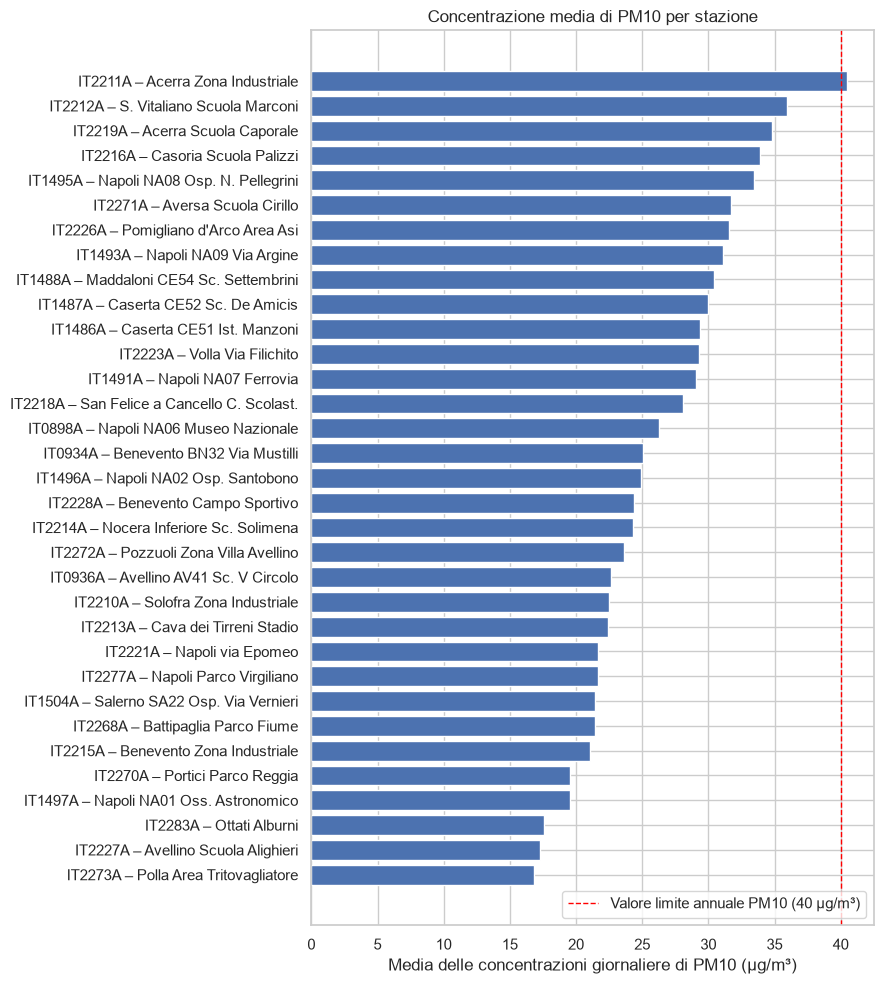

          mean  count
Stazione             
IT2211A   40.5   1005
IT2212A   35.9   1119
IT2219A   34.8   1120
IT2216A   33.9   1123
IT1495A   33.4   1064
IT2271A   31.7   1078
IT2226A   31.6    918
IT1493A   31.1   1049
IT1488A   30.4   1142
IT1487A   30.0   1094
IT1486A   29.4    949
IT2223A   29.3   1120
IT1491A   29.1   1024
IT2218A   28.1   1098
IT0898A   26.3   1048
IT0934A   25.1    970
IT1496A   24.9   1114
IT2228A   24.4   1149
IT2214A   24.3   1106
IT2272A   23.6    645
IT0936A   22.6   1056
IT2210A   22.5   1138
IT2213A   22.4   1116
IT2221A   21.7   1106
IT2277A   21.7    906
IT1504A   21.5   1042
IT2268A   21.4   1059
IT2215A   21.0   1117
IT2270A   19.6   1110
IT1497A   19.5   1112
IT2283A   17.6    998
IT2227A   17.3   1138
IT2273A   16.8   1111


In [10]:
pm10 = giornaliero[giornaliero["Inquinante"] == "PM10"]

nomi = df.groupby("Stazione")["Descrizione"].last().str.replace(r"[°*]", "", regex=True).str.strip()

stat = pm10.groupby("Stazione")["mean"].agg(["mean", "count"])
stat = stat[stat["count"] >= 365]
stat["etichetta"] = [f"{codice} – {nomi[codice]}" for codice in stat.index]
stat = stat.sort_values("mean")

plt.figure(figsize=(9, 10))
plt.barh(stat["etichetta"], stat["mean"])
plt.axvline(40, color="red", linestyle="--", linewidth=1, label="Valore limite annuale PM10 (40 µg/m³)")
plt.xlabel("Media delle concentrazioni giornaliere di PM10 (µg/m³)")
plt.title("Concentrazione media di PM10 per stazione")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES / "media_per_stazione.png", dpi=200)
plt.show()

print(stat.sort_values("mean", ascending=False)[["mean", "count"]].round(1))

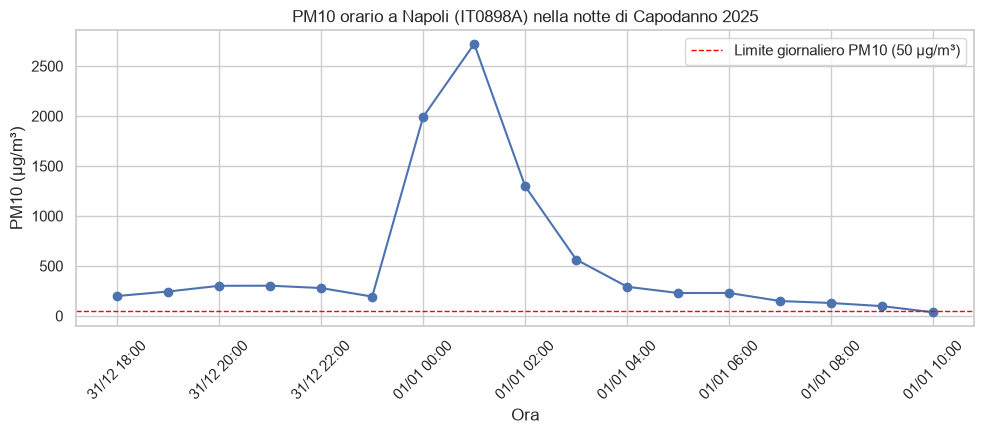

In [11]:
masque = (
    (df["Stazione"] == "IT0898A")
    & (df["Inquinante"] == "PM10")
    & (df["Data_ora"].between("2024-12-31 18:00", "2025-01-01 10:00"))
)
capodanno = df[masque]

plt.figure(figsize=(10, 4.5))
plt.plot(capodanno["Data_ora"], capodanno["Valore"], marker="o")
plt.axhline(50, color="red", linestyle="--", linewidth=1, label="Limite giornaliero PM10 (50 µg/m³)")
plt.ylabel("PM10 (µg/m³)")
plt.xlabel("Ora")
plt.title("PM10 orario a Napoli (IT0898A) nella notte di Capodanno 2025")
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m %H:%M"))
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "capodanno_2025.png", dpi=200)
plt.show()

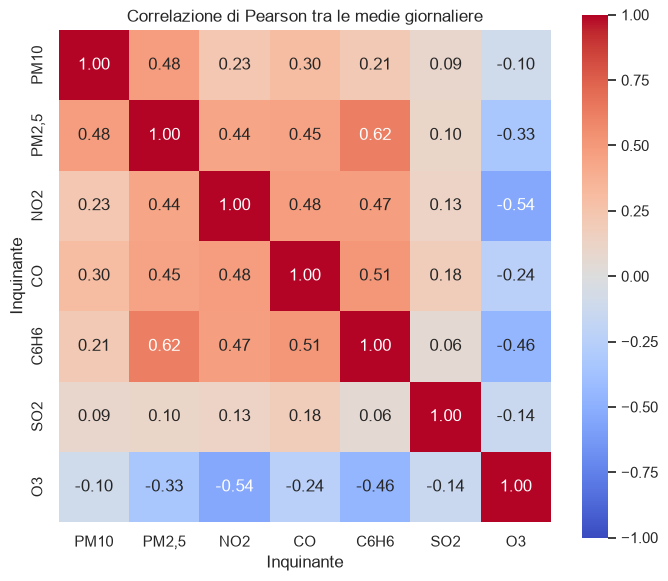

pearson 
 Inquinante  PM10  PM2,5   NO2    CO  C6H6   SO2    O3
Inquinante                                           
PM10        1.00   0.48  0.23  0.30  0.21  0.09 -0.10
PM2,5       0.48   1.00  0.44  0.45  0.62  0.10 -0.33
NO2         0.23   0.44  1.00  0.48  0.47  0.13 -0.54
CO          0.30   0.45  0.48  1.00  0.51  0.18 -0.24
C6H6        0.21   0.62  0.47  0.51  1.00  0.06 -0.46
SO2         0.09   0.10  0.13  0.18  0.06  1.00 -0.14
O3         -0.10  -0.33 -0.54 -0.24 -0.46 -0.14  1.00 



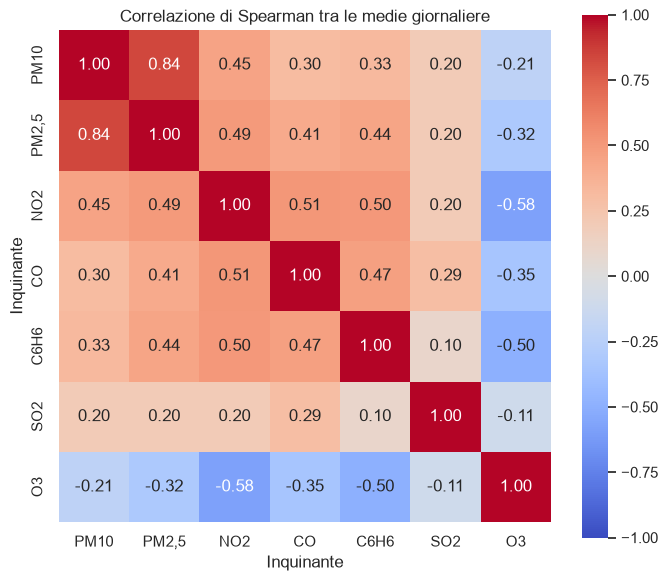

spearman 
 Inquinante  PM10  PM2,5   NO2    CO  C6H6   SO2    O3
Inquinante                                           
PM10        1.00   0.84  0.45  0.30  0.33  0.20 -0.21
PM2,5       0.84   1.00  0.49  0.41  0.44  0.20 -0.32
NO2         0.45   0.49  1.00  0.51  0.50  0.20 -0.58
CO          0.30   0.41  0.51  1.00  0.47  0.29 -0.35
C6H6        0.33   0.44  0.50  0.47  1.00  0.10 -0.50
SO2         0.20   0.20  0.20  0.29  0.10  1.00 -0.11
O3         -0.21  -0.32 -0.58 -0.35 -0.50 -0.11  1.00 



In [13]:
pm10[(pm10["Stazione"] == "IT1486A") & (pm10["mean"] < 1000)]["mean"].mean()

tabella = giornaliero.pivot_table(index=["Stazione", "giorno"], columns="Inquinante", values="mean")
ordine = ["PM10", "PM2,5", "NO2", "CO", "C6H6", "SO2", "O3"]
tabella = tabella[ordine]

for metodo, nome_file in [("pearson", "correlazione_pearson.png"), ("spearman", "correlazione_spearman.png")]:
    corr = tabella.corr(method=metodo)
    plt.figure(figsize=(7, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
    plt.title(f"Correlazione di {metodo.capitalize()} tra le medie giornaliere")
    plt.tight_layout()
    plt.savefig(FIGURES / nome_file, dpi=200)
    plt.show()
    print(metodo, "\n", corr.round(2), "\n")

In [14]:
giornaliero.groupby("Inquinante")["mean"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Inquinante,,,,,,,,
C6H6,24309.0,1.0,1.0,0.0,0.4,0.7,1.2,22.2
CO,21678.0,0.5,0.3,0.0,0.3,0.4,0.6,18.4
NO2,38913.0,23.0,14.8,0.0,12.1,20.3,31.0,212.9
O3,21635.0,56.1,23.0,0.0,39.7,56.5,71.6,529.0
PM10,35057.0,26.1,30.2,0.0,14.8,21.8,31.4,2453.0
"PM2,5",35186.0,13.9,12.0,0.0,7.5,11.4,16.8,345.0
SO2,14392.0,2.8,3.5,0.0,1.0,2.2,3.7,289.5
